In [1]:
import numpy as np
import matplotlib.pyplot as plt
from html import escape
from IPython.display import HTML, display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

def show_table(columns, rows, caption=''):
    """Таблица для Jupyter и Colab без дополнительных библиотек."""
    def cell(value):
        if isinstance(value, (float, np.floating)):
            value = f'{value:.6g}'
        return escape(str(value))
    header = ''.join(f'<th>{cell(v)}</th>' for v in columns)
    body = ''.join('<tr>' + ''.join(f'<td>{cell(v)}</td>' for v in row) + '</tr>'
                   for row in rows)
    title = f'<caption>{escape(caption)}</caption>' if caption else ''
    display(HTML(f'<table>{title}<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

## Образы

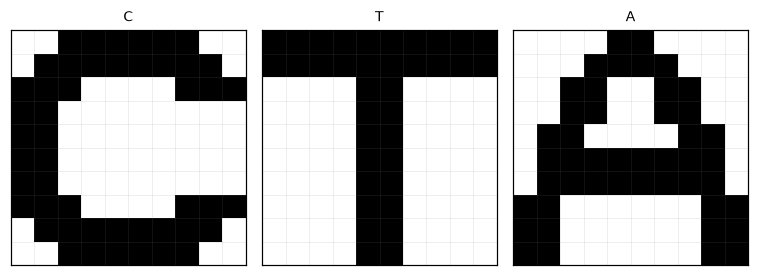

In [2]:
LETTERS = {
    'С': ['..######..', '.########.', '###....###', '##........', '##........',
          '##........', '##........', '###....###', '.########.', '..######..'],
    'Т': ['##########', '##########', '....##....', '....##....', '....##....',
          '....##....', '....##....', '....##....', '....##....', '....##....'],
    'А': ['....##....', '...####...', '..##..##..', '..##..##..', '.##....##.',
          '.########.', '.########.', '##......##', '##......##', '##......##'],
}
LETTER_NAMES = list(LETTERS)
assert all(len(rows) == 10 and all(len(row) == 10 for row in rows) for rows in LETTERS.values())
PATTERNS = np.array([[1 if pixel == '#' else -1 for row in LETTERS[name] for pixel in row]
                     for name in LETTER_NAMES], dtype=np.int64)
NOISE_LEVELS = [10, 20, 30, 35, 40, 45, 50, 60, 70, 80, 90, 100]
SEED = 16
BASIC_TRIALS = 10
EXTENDED_TRIALS = 200
MAX_SWEEPS = 100

def draw_pattern(ax, vector, title):
    ax.imshow(vector.reshape(10, 10), cmap='gray_r', vmin=-1, vmax=1)
    ax.set_xticks(np.arange(-.5, 10), minor=True)
    ax.set_yticks(np.arange(-.5, 10), minor=True)
    ax.grid(which='minor', color='gray', linewidth=.35)
    ax.grid(which='major', visible=False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(which='minor', length=0)
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, name, pattern in zip(axes, LETTER_NAMES, PATTERNS):
    draw_pattern(ax, pattern, name)
fig.tight_layout()
plt.show()

## Обучение

Буква,Устойчива,Энергия
С,True,-5058
Т,True,-5146
А,True,-5338


Скалярное произведение,С,Т,А
С,100,4,-20
Т,4,100,-24
А,-20,-24,100


Оценка ёмкости по формуле задания: 9.31 образа.
Эта оценка не заменяет проверку устойчивости конкретных образов.


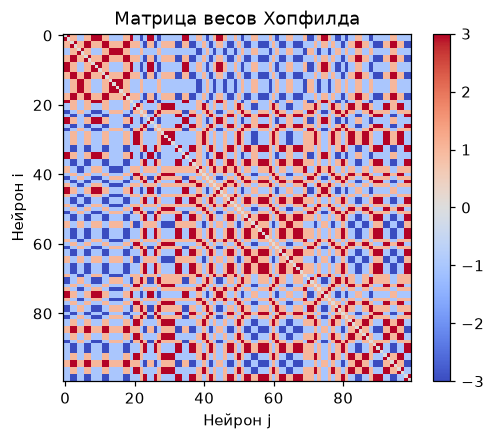

In [3]:
WEIGHTS = PATTERNS.T @ PATTERNS
np.fill_diagonal(WEIGHTS, 0)

def activation(field):
    return np.where(field > 0, 1, -1)

def energy(state):
    return float(-0.5 * state @ WEIGHTS @ state)

def identify(state):
    for name, pattern in zip(LETTER_NAMES, PATTERNS):
        if np.array_equal(state, pattern):
            return name
        if np.array_equal(state, -pattern):
            return 'Негатив ' + name
    return 'Ложный образ'

show_table(['Буква', 'Устойчива', 'Энергия'],
           [[name, np.array_equal(activation(WEIGHTS @ pattern), pattern), energy(pattern)]
            for name, pattern in zip(LETTER_NAMES, PATTERNS)])
show_table(['Скалярное произведение', *LETTER_NAMES],
           [[name, *row] for name, row in zip(LETTER_NAMES, PATTERNS @ PATTERNS.T)])
neuron_count = PATTERNS.shape[1]
capacity_estimate = neuron_count / (2 * np.log(neuron_count) + np.log(np.log(neuron_count)))
print(f'Оценка ёмкости по формуле задания: {capacity_estimate:.2f} образа.')
print('Эта оценка не заменяет проверку устойчивости конкретных образов.')
fig, ax = plt.subplots(figsize=(4.8, 4))
heat = ax.imshow(WEIGHTS, cmap='coolwarm', vmin=-len(PATTERNS), vmax=len(PATTERNS))
ax.grid(False)
ax.set(title='Матрица весов Хопфилда', xlabel='Нейрон j', ylabel='Нейрон i')
fig.colorbar(heat, ax=ax)
fig.tight_layout()
plt.show()

## Восстановление

In [4]:
from dataclasses import dataclass

@dataclass
class RecallResult:
    state: np.ndarray
    passes: int
    status: str
    energies: tuple = ()

def recall_sync(initial, limit=MAX_SWEEPS):
    state = np.array(initial, dtype=np.int64, copy=True)
    seen = {state.tobytes(): 0}
    for step in range(1, limit + 1):
        updated = activation(WEIGHTS @ state)
        if np.array_equal(updated, state):
            return RecallResult(updated, step, 'Устойчивое состояние')
        key = updated.tobytes()
        if key in seen:
            return RecallResult(updated, step, f'Цикл длины {step - seen[key]}')
        seen[key] = step
        state = updated
    return RecallResult(state, limit, 'Лимит итераций')

def recall_async(initial, order_rng, limit=MAX_SWEEPS, record_energy=False):
    state = np.array(initial, dtype=np.int64, copy=True)
    fields = WEIGHTS @ state
    current_energy = energy(state) if record_energy else 0.0
    trace = [current_energy] if record_energy else []
    for sweep in range(1, limit + 1):
        changed = False
        for neuron in order_rng.permutation(len(state)):
            updated = 1 if fields[neuron] > 0 else -1
            delta = updated - state[neuron]
            if delta:
                if record_energy:
                    current_energy -= delta * fields[neuron]
                state[neuron] = updated
                fields += delta * WEIGHTS[:, neuron]
                changed = True
            if record_energy:
                trace.append(current_energy)
        if not changed:
            return RecallResult(state, sweep, 'Устойчивое состояние', tuple(trace))
    return RecallResult(state, limit, 'Лимит итераций', tuple(trace))

def corrupt(pattern, noise_percent, noise_rng):
    if not 0 <= noise_percent <= 100:
        raise ValueError('Процент шума должен находиться между 0 и 100')
    noisy = pattern.copy()
    count = round(len(pattern) * noise_percent / 100)
    noisy[noise_rng.choice(len(pattern), count, replace=False)] *= -1
    return noisy

## Эксперимент

In [5]:
def run_experiment(trials, seed):
    if trials < 10:
        raise ValueError('По заданию требуется не менее десяти испытаний на букву')
    seeds = np.random.SeedSequence(seed).spawn(2)
    noise_rng, order_rng = [np.random.default_rng(s) for s in seeds]
    rates = np.zeros((len(NOISE_LEVELS), len(PATTERNS), 2))
    outcomes = []
    for level_i, level in enumerate(NOISE_LEVELS):
        for letter_i, (name, pattern) in enumerate(zip(LETTER_NAMES, PATTERNS)):
            correct = np.zeros(2, dtype=int)
            for _ in range(trials):
                noisy = corrupt(pattern, level, noise_rng)
                sync = recall_sync(noisy)
                asynchronous = recall_async(noisy, order_rng)
                correct += [np.array_equal(sync.state, pattern),
                            np.array_equal(asynchronous.state, pattern)]
                label = identify(asynchronous.state)
                category = ('Верно' if label == name else 'Другая буква' if label in LETTER_NAMES
                            else 'Негатив' if label.startswith('Негатив') else 'Ложный образ')
                outcomes.append((level, name, category, sync.status, asynchronous.status))
            rates[level_i, letter_i] = correct * 100 / trials
    return {'rates': rates, 'outcomes': outcomes, 'trials': trials}

def show_accuracy(experiment):
    columns = ['Шум, %'] + [f'{name}: {mode}' for name in LETTER_NAMES for mode in ['синхр.', 'асинхр.']]
    rows = [[level, *[f'{v:.1f}' for v in experiment['rates'][i].ravel()]]
            for i, level in enumerate(NOISE_LEVELS)]
    show_table(columns, rows, f'Верно распознано, %; испытаний на букву: {experiment["trials"]}')

basic = run_experiment(BASIC_TRIALS, SEED)
show_accuracy(basic)
categories = ['Верно', 'Другая буква', 'Ложный образ', 'Негатив']
outcome_counts = [[level, *[sum(row[0] == level and row[2] == category for row in basic['outcomes'])
                           for category in categories]] for level in NOISE_LEVELS]
show_table(['Шум, %', *categories], outcome_counts, 'Исходы асинхронного восстановления')

"Шум, %",С: синхр.,С: асинхр.,Т: синхр.,Т: асинхр.,А: синхр.,А: асинхр.
10,100.0,100.0,100.0,100.0,100.0,100.0
20,100.0,100.0,100.0,100.0,100.0,100.0
30,100.0,90.0,100.0,100.0,100.0,100.0
35,100.0,100.0,100.0,100.0,90.0,70.0
40,40.0,50.0,40.0,40.0,90.0,90.0
45,60.0,50.0,30.0,50.0,40.0,40.0
50,0.0,0.0,0.0,10.0,0.0,0.0
60,0.0,0.0,0.0,0.0,0.0,0.0
70,0.0,0.0,0.0,0.0,0.0,0.0
80,0.0,0.0,0.0,0.0,0.0,0.0


"Шум, %",Верно,Другая буква,Ложный образ,Негатив
10,30,0,0,0
20,30,0,0,0
30,29,0,1,0
35,27,0,2,1
40,18,0,10,2
45,14,3,12,1
50,1,13,3,13
60,0,2,5,23
70,0,0,0,30
80,0,0,0,30


"Шум, %",С: синхр.,С: асинхр.,Т: синхр.,Т: асинхр.,А: синхр.,А: асинхр.
10,100.0,100.0,100.0,100.0,100.0,100.0
20,100.0,100.0,100.0,100.0,100.0,100.0
30,98.5,98.5,97.0,96.5,97.5,96.5
35,93.0,92.0,89.5,94.0,90.0,85.0
40,67.5,69.0,72.0,74.5,73.5,71.0
45,25.0,33.0,39.0,39.5,36.5,32.0
50,0.0,1.0,0.0,0.0,0.0,0.5
60,0.0,0.0,0.0,0.0,0.0,0.0
70,0.0,0.0,0.0,0.0,0.0,0.0
80,0.0,0.0,0.0,0.0,0.0,0.0


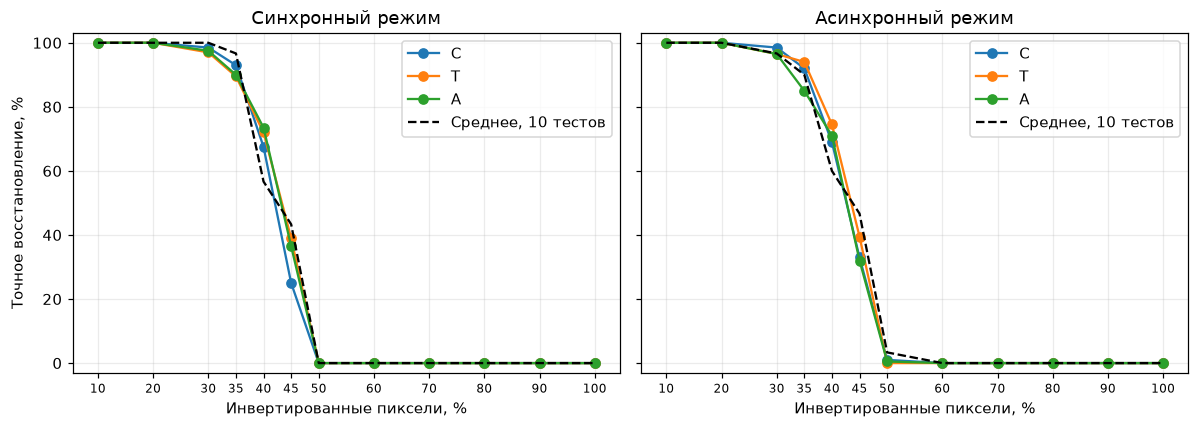

"Шум, %",Устойчивое состояние,Цикл длины 2
10,600,0
20,600,0
30,600,0
35,600,0
40,600,0
45,600,0
50,585,15
60,600,0
70,600,0
80,600,0


In [6]:
extended = run_experiment(EXTENDED_TRIALS, SEED + 1)
show_accuracy(extended)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for mode_i, (ax, title) in enumerate(zip(axes, ['Синхронный режим', 'Асинхронный режим'])):
    for letter_i, name in enumerate(LETTER_NAMES):
        ax.plot(NOISE_LEVELS, extended['rates'][:, letter_i, mode_i], 'o-', label=name)
    ax.plot(NOISE_LEVELS, basic['rates'][:, :, mode_i].mean(axis=1), 'k--',
            label=f'Среднее, {BASIC_TRIALS} тестов')
    ax.set(title=title, xlabel='Инвертированные пиксели, %', ylim=(-3, 103))
    ax.set_xticks(NOISE_LEVELS)
    ax.tick_params(axis='x', labelsize=8)
    ax.legend()
axes[0].set_ylabel('Точное восстановление, %')
fig.tight_layout()
plt.show()
statuses = sorted(set(row[3] for row in extended['outcomes']))
show_table(['Шум, %', *statuses],
           [[level, *[sum(row[0] == level and row[3] == status for row in extended['outcomes'])
                      for status in statuses]] for level in NOISE_LEVELS], 'Состояния синхронного режима')

## Примеры

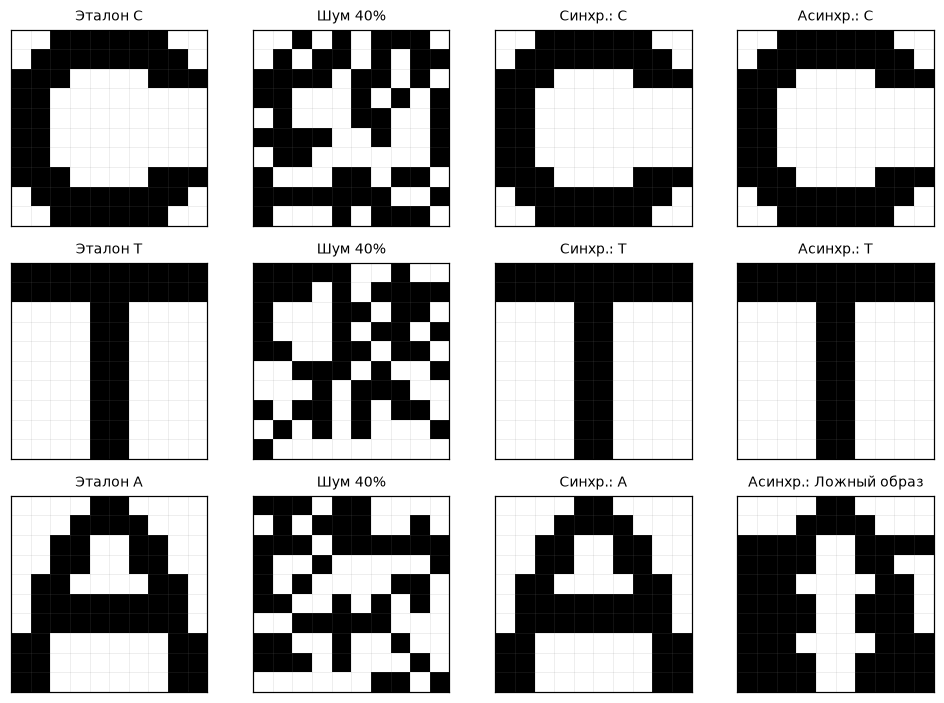

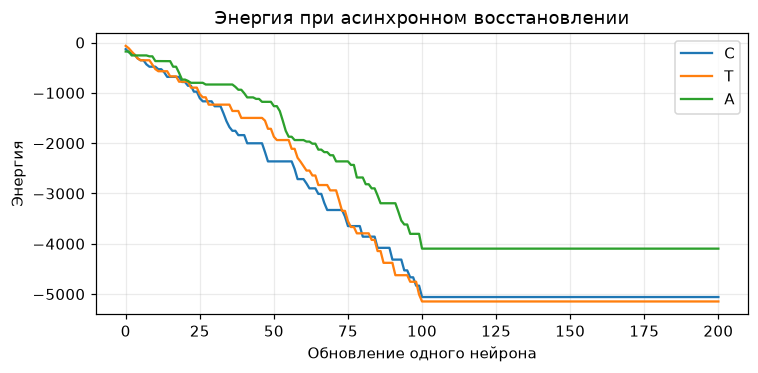

In [7]:
DEMO_NOISE = 40
DEMO_SEED = 41
fig, axes = plt.subplots(3, 4, figsize=(9, 6.5))
energy_traces = []
for i, (name, pattern) in enumerate(zip(LETTER_NAMES, PATTERNS)):
    noisy = corrupt(pattern, DEMO_NOISE, np.random.default_rng(DEMO_SEED + i))
    out_sync = recall_sync(noisy)
    out_async = recall_async(noisy, np.random.default_rng(DEMO_SEED + 100 + i), record_energy=True)
    energy_traces.append(out_async.energies)
    assert np.all(np.diff(out_async.energies) <= 1e-10)
    assert np.isclose(out_async.energies[-1], energy(out_async.state))
    for ax, state, title in zip(axes[i], [pattern, noisy, out_sync.state, out_async.state],
                                [f'Эталон {name}', f'Шум {DEMO_NOISE}%',
                                 'Синхр.: ' + identify(out_sync.state), 'Асинхр.: ' + identify(out_async.state)]):
        draw_pattern(ax, state, title)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, trace in zip(LETTER_NAMES, energy_traces):
    ax.plot(trace, label=name)
ax.set(xlabel='Обновление одного нейрона', ylabel='Энергия', title='Энергия при асинхронном восстановлении')
ax.legend()
fig.tight_layout()
plt.show()

## Проверки

In [8]:
assert np.array_equal(WEIGHTS, WEIGHTS.T)
assert not np.diag(WEIGHTS).any()
assert PATTERNS.shape == (3, 100)
check_rng = np.random.default_rng(0)
for pattern in PATTERNS:
    assert np.array_equal(activation(WEIGHTS @ pattern), pattern)
    for level in [0, *NOISE_LEVELS]:
        assert np.count_nonzero(corrupt(pattern, level, check_rng) != pattern) == round(len(pattern) * level / 100)
    assert np.array_equal(recall_sync(-pattern).state, -pattern)
    assert np.array_equal(recall_async(-pattern, check_rng).state, -pattern)
for experiment in [basic, extended]:
    assert np.all((experiment['rates'] >= 0) & (experiment['rates'] <= 100))
    assert len(experiment['outcomes']) == len(NOISE_LEVELS) * len(PATTERNS) * experiment['trials']
assert all(sum(row[1:]) == len(PATTERNS) * BASIC_TRIALS for row in outcome_counts)
print('Проверки весов, шума, негативов и числа испытаний пройдены.')

Проверки весов, шума, негативов и числа испытаний пройдены.
